In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix,precision_score, recall_score,f1_score,roc_curve, roc_auc_score

# Load the Iris dataset
iris = load_iris()

# Create a DataFrame from the data
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)

# Add the target variable (species) to the DataFrame
df['target'] = iris.target

print("\nDataset Info:")
df.info()

print("\nDataset Description:")
display(df.describe())


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Dataset Description:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [ ]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df.drop('target', axis=1) # Features are all columns except 'target'
y = df['target'] # Target is the 'target' column (species)

# Split the data into training and testing sets
# test_size=0.3 means 30% of the data will be used for testing
# random_state ensures reproducibility
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Shape of X_train: (105, 4)
Shape of X_test: (45, 4)
Shape of y_train: (105,)
Shape of y_test: (45,)


In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_pred

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 1, 0, 0, 2, 1, 0, 0, 0, 2, 1, 1, 0,
       0])

### Model Evaluation

In [ ]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted'):.4f}")
print(f"Recall: {recall_score(y_test, y_pred, average='weighted'):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred, average='weighted'):.4f}")

Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000


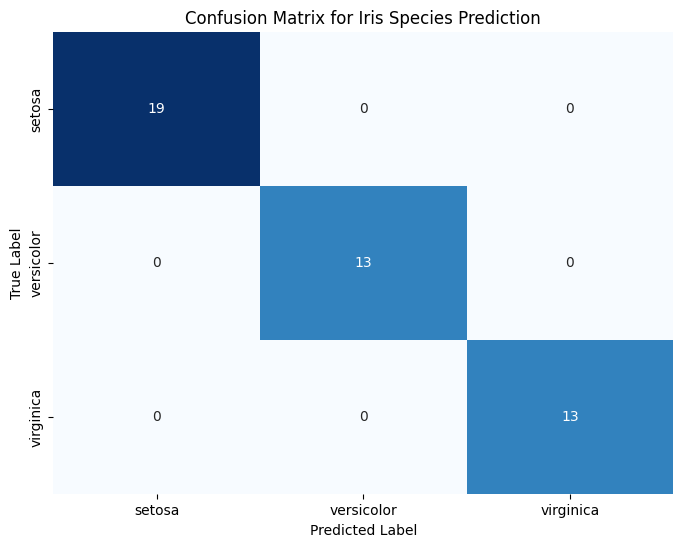

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Iris Species Prediction')
plt.show()

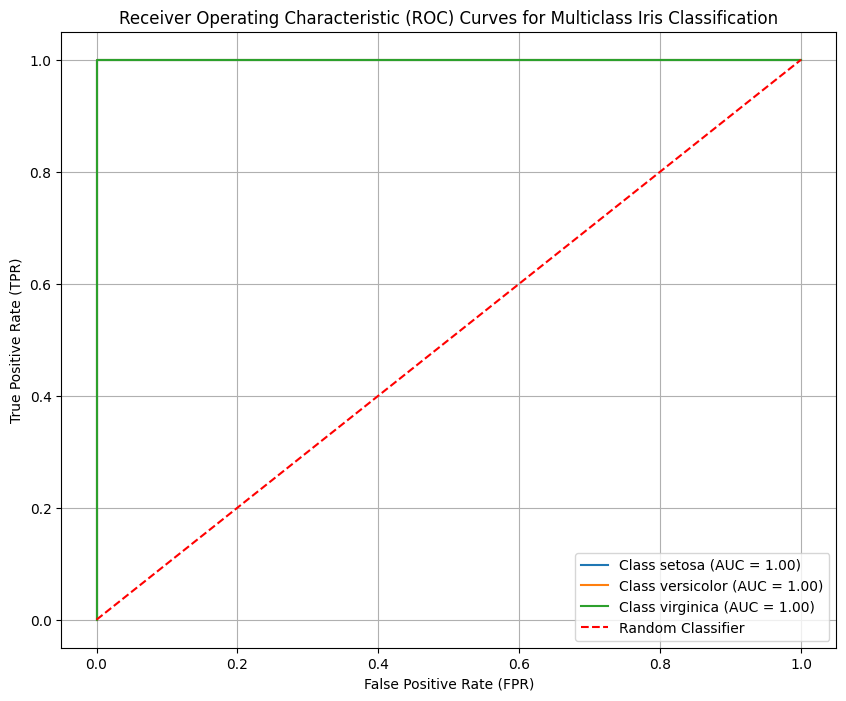

In [ ]:
from sklearn.preprocessing import LabelBinarizer

# Get predicted probabilities for each class
y_pred_proba = model.predict_proba(X_test)

# Binarize the true labels for one-vs-rest ROC calculation
label_binarizer = LabelBinarizer()
y_test_binarized = label_binarizer.fit_transform(y_test)

plt.figure(figsize=(10, 8))

# Plot ROC curve for each class (One-vs-Rest)
for i in range(len(iris.target_names)):
    fpr, tpr, _ = roc_curve(y_test_binarized[:, i], y_pred_proba[:, i])
    roc_auc = roc_auc_score(y_test_binarized[:, i], y_pred_proba[:, i])
    plt.plot(fpr, tpr, label=f'Class {iris.target_names[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curves for Multiclass Iris Classification')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

### Classify New Input

In [ ]:
# Example new input (replace with your actual 4 feature values for Iris)
# This should be a 2D array, even for a single sample.
# Make sure the order of features matches the training data: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
new_input = np.array([5.1, 3.5, 1.4, 0.2]) # Example for Setosa

# Reshape the input to be a 2D array since the scaler and model expect it
new_input = new_input.reshape(1, -1)

print("Original New Input:")
display(new_input)

Original New Input:


array([[5.1, 3.5, 1.4, 0.2]])

In [ ]:
# Preprocess the new input using the same scaler fitted on the training data
scaled_new_input = scaler.transform(new_input)

print("Scaled New Input:")
display(scaled_new_input)

Scaled New Input:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([[-0.89573553,  1.17645543, -1.44207638, -1.40568508]])

In [ ]:
# Make a prediction using the trained model
prediction = model.predict(scaled_new_input)

# Interpret the prediction
iris_species = {
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
}
result = iris_species[prediction[0]]

print(f"The model predicts the species is: {result} (Label: {prediction[0]}) ")

The model predicts the species is: Setosa (Label: 0) 


In [ ]:
# ============================================================
# 12. CREATE GUI INPUT FIELDS
# ============================================================
from IPython.display import display, HTML
import ipywidgets as widgets

sepal_length = widgets.FloatText(
    value=5.1,
    description="Sepal Length:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

sepal_width = widgets.FloatText(
    value=3.5,
    description="Sepal Width:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

petal_length = widgets.FloatText(
    value=1.4,
    description="Petal Length:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

petal_width = widgets.FloatText(
    value=0.2,
    description="Petal Width:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

In [ ]:
# ============================================================
# 13. CREATE BUTTONS AND RESULT AREA
# ============================================================

predict_button = widgets.Button(
    description="Predict",
    button_style="primary",
    icon="check",
    layout=widgets.Layout(width="150px", height="40px")
)

clear_button = widgets.Button(
    description="Clear",
    button_style="warning",
    icon="refresh",
    layout=widgets.Layout(width="150px", height="40px")
)

result = widgets.HTML(
    value="",
    layout=widgets.Layout(
        width="100%",
        margin="20px 0px 0px 0px"
    )
)

# ============================================================
# 14. PREDICTION FUNCTION
# ============================================================

def predict_iris(button):

    # Collect values
    new_input = np.array([[
        sepal_length.value,
        sepal_width.value,
        petal_length.value,
        petal_width.value
    ]])

    # Scale input using the SAME scaler
    scaled_input = scaler.transform(new_input)

    # Prediction
    prediction = model.predict(scaled_input)[0]

    # Prediction probabilities
    probabilities = model.predict_proba(scaled_input)[0]

    # Confidence
    confidence = np.max(probabilities) * 100

    # Species mapping
    iris_species = {
        0: "Setosa",
        1: "Versicolor",
        2: "Virginica"
    }

    predicted_species = iris_species[prediction]

    # Result styling
    if predicted_species == "Setosa":
        text_color = "white"

    elif predicted_species == "Versicolor":
        text_color = "white"

    else:
        text_color = "white"

    # Display result
    result.value = f"""
    <div style="
        color: {text_color};
        padding: 20px;
        border-radius: 12px;
        text-align: center;
        width: 100%;
        box-sizing: border-box;
    ">

        <h2 style="margin: 5px 0;">
            Prediction: {predicted_species.upper()}
        </h2>

        <p style="
            font-size: 18px;
            margin: 10px 0;
        ">
            Model Confidence:
            <strong>{confidence:.2f}%</strong>
        </p>

    </div>
    """

def clear_form(button):

    # Reset values
    sepal_length.value = 5.1
    sepal_width.value = 3.5
    petal_length.value = 1.4
    petal_width.value = 0.2

    # Clear prediction
    result.value = ""


predict_button.on_click(predict_iris)

clear_button.on_click(clear_form)

title = widgets.HTML(
    """
    <div style="
        background: #007bff;
        color: black;
        padding: 20px;
        border-radius: 12px;
        text-align: center;
        margin-bottom: 20px;
    ">

        <h1 style="margin: 0;">
            Iris Species Prediction System
        </h1>

        <p style="
            margin: 8px 0 0 0;
            font-size: 16px;
        ">
            Logistic Regression Model
        </p>

    </div>
    """
)

input_title = widgets.HTML(
    """
    <h3 style="
        margin-top: 10px;
        margin-bottom: 10px;
    ">
        Enter Flower Measurements
    </h3>
    """
)

buttons = widgets.HBox(
    [
        predict_button,
        clear_button
    ],
    layout=widgets.Layout(
        justify_content="center",
        gap="15px",
        margin="20px 0px"
    )
)


gui = widgets.VBox(
    [
        title,
        input_title,
        sepal_length,
        sepal_width,
        petal_length,
        petal_width,
        buttons,
        result,
    ],
    layout=widgets.Layout(
        width="600px",
        margin="auto"
    )
)

display(gui)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut